Connected to fvc_structure (Python 3.10.18)

In [ ]:
import sys
import numpy as np
import rasterio
import time
import pylab as pl
from pathlib import Path
from rasterio.warp import reproject, Resampling

# === GeFolki dependencies ===
# Workstation
# sys.path.append('/media/laura/laura_usb/code/fvc_structure/phase_1_image_processing/gefolki/python')
# === GeFolki dependencies === NVIDIA
sys.path.append('/home/nvidia/projects/fvc_structure/phase_2_lidar_coregistration/gefolki/python')

from python.algorithm import EFolki
from python.tools import wrapData

# === Configuration ===
Base_band = 0

# === Input paths ===
# Workstation
# base_image_path   = Path("/media/laura/laura_usb/uas_data/DD0001/imagery/dsm/SASMDD0001_rgb_dsm_03.tif")
# moving_image_path = Path("/media/laura/laura_usb/uas_data/DD0001/lidar_l2/dsm/crop_to_rgb/SASMDD0001_l2_dsm_03.tif")

# NVIDIA
base_image_path = Path("/data/calperumResearch/site1_1_DD0001/imagery/dsm/SASMDD0001_rgb_dsm_03.tif")

moving_image_path = Path("/data/calperumResearch/site1_1_DD0001/lidar_l2/dsm/crop_to_rgb/SASMDD0001_l2_dsm_03.tif")

In [ ]:
# === Function Definitions ===

def load_data_and_mask(path, band_idx):
    """Load raster band data with its valid data mask (True=valid, False=nodata)."""
    with rasterio.open(path) as src:
        if band_idx >= src.count:
            raise ValueError(f"Band {band_idx} out of range for {path}")
        valid_mask = src.read_masks(band_idx + 1) > 0
        arr = src.read(band_idx + 1).astype(np.float32)
        arr[~valid_mask] = 0
        return arr, valid_mask

def preprocess_dsm(arr, mask):
    """Remove absolute offset and normalize for EFolki."""
    arr = arr.astype(np.float32)
    arr[~mask] = np.nan
    arr = arr - np.nanmean(arr)          # remove mean (offset)
    arr = arr / (np.nanstd(arr) + 1e-6)  # standardize contrast
    arr[np.isnan(arr)] = 0
    return arr

In [ ]:
# === Load Input Rasters ===
base_data, base_mask = load_data_and_mask(base_image_path, Base_band)
moving_data, moving_mask = load_data_and_mask(moving_image_path, 0)

# === Verify Metadata Consistency ===
with rasterio.open(base_image_path) as base_src, rasterio.open(moving_image_path) as mov_src:
    if base_src.crs != mov_src.crs:
        print(f"⚠️ CRS mismatch: {base_src.crs} vs {mov_src.crs}")
    if base_src.res != mov_src.res:
        print(f"⚠️ Resolution mismatch: {base_src.res} vs {mov_src.res}")
    if base_src.transform != mov_src.transform:
        print("⚠️ Pixel grid differs → Reprojecting LiDAR DSM to RGB grid.")
        dst = np.empty_like(base_data)
        reproject(
            source=moving_data,
            destination=dst,
            src_transform=mov_src.transform,
            src_crs=mov_src.crs,
            dst_transform=base_src.transform,
            dst_crs=base_src.crs,
            resampling=Resampling.bilinear
        )
        moving_data = dst

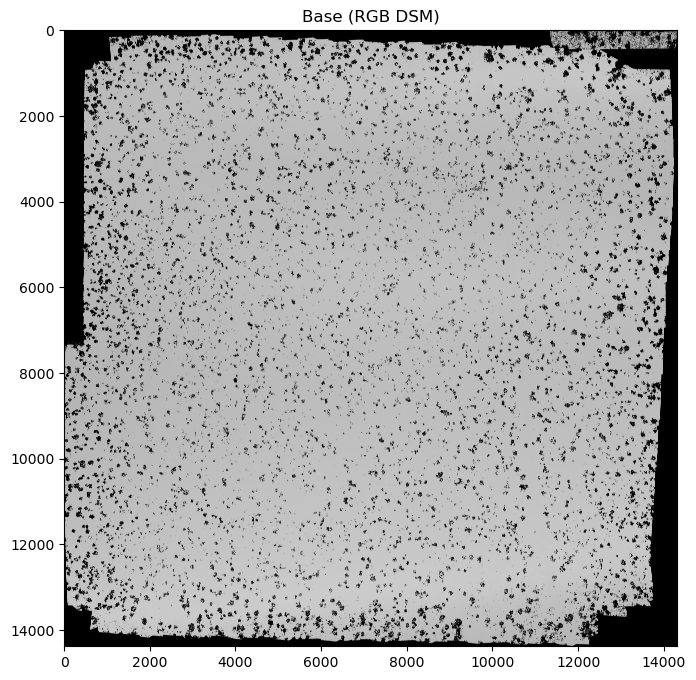

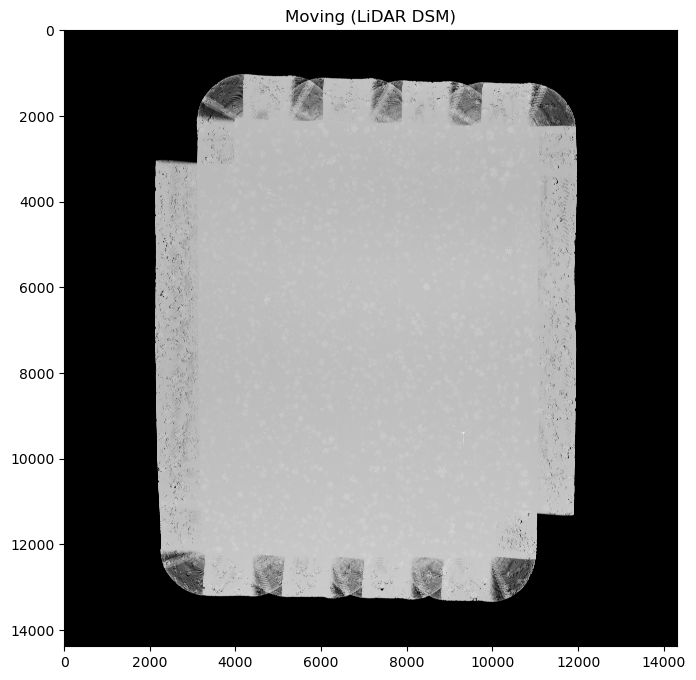

In [ ]:
# === Initial Visualization ===
pl.figure(figsize=(8,8))
pl.imshow(base_data, cmap='gray')
pl.title("Base (RGB DSM)")

pl.figure(figsize=(8,8))
pl.imshow(moving_data, cmap='gray')
pl.title("Moving (LiDAR DSM)")

pl.show()

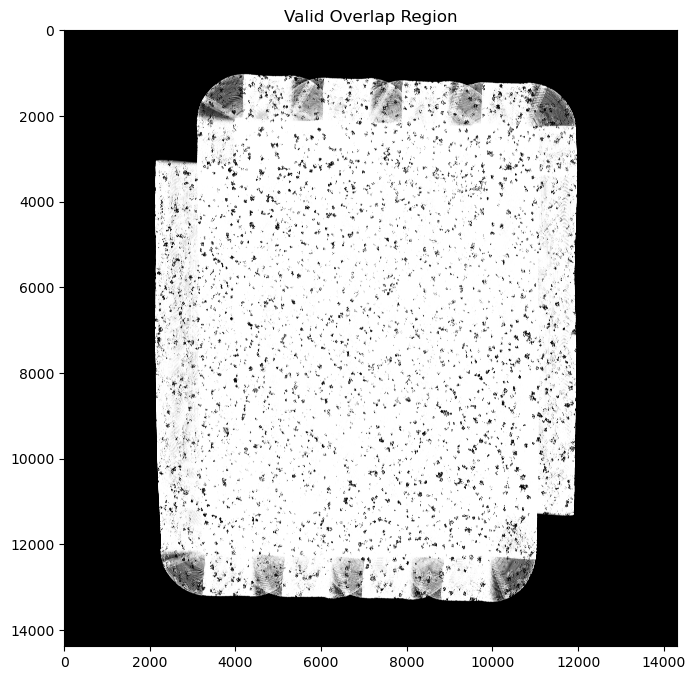

In [ ]:
# === Define Processing Mask ===
processing_mask = base_mask & moving_mask
base_data[~processing_mask] = 0
moving_data[~processing_mask] = 0

pl.figure(figsize=(8,8))
pl.imshow(processing_mask, cmap='gray')
pl.title("Valid Overlap Region")
pl.show()

In [ ]:
# === Normalize Inputs ===
base_norm   = preprocess_dsm(base_data, processing_mask)
moving_norm = preprocess_dsm(moving_data, processing_mask)

🔹 Calculating optical flow (EFolki)...
✅ Flow calculated in 36.567 minutes
Mean flow: u=11.640, v=-36.714, std(u)=18.537, std(v)=49.006


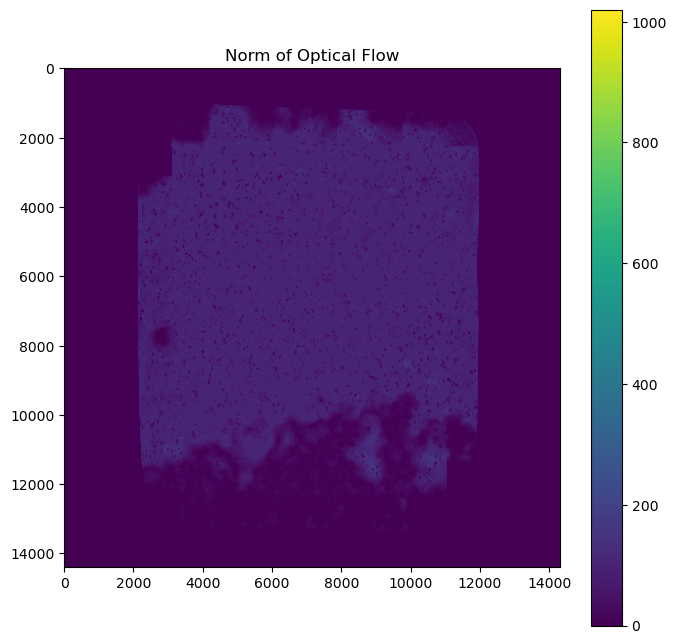

In [ ]:
# === Run GeFolki Optical Flow ===
print("🔹 Calculating optical flow (EFolki)...")
t0 = time.perf_counter()

u, v = EFolki(base_norm, moving_norm,
              iteration=8,
              radius=[8, 4, 2],
              rank=4,
              levels=6)

t1 = time.perf_counter()
print(f"✅ Flow calculated in {(t1 - t0)/60:.3f} minutes")

# Mask flow outside valid region
u[~processing_mask] = 0
v[~processing_mask] = 0

# Flow diagnostics
print(f"Mean flow: u={np.nanmean(u):.3f}, v={np.nanmean(v):.3f}, std(u)={np.nanstd(u):.3f}, std(v)={np.nanstd(v):.3f}")

# Visualize flow norm
N = np.sqrt(u**2 + v**2)
pl.figure(figsize=(8,8))
pl.imshow(N, cmap='viridis')
pl.title("Norm of Optical Flow")
pl.colorbar()
pl.show()

🔹 Warping LiDAR DSM to RGB DSM space...


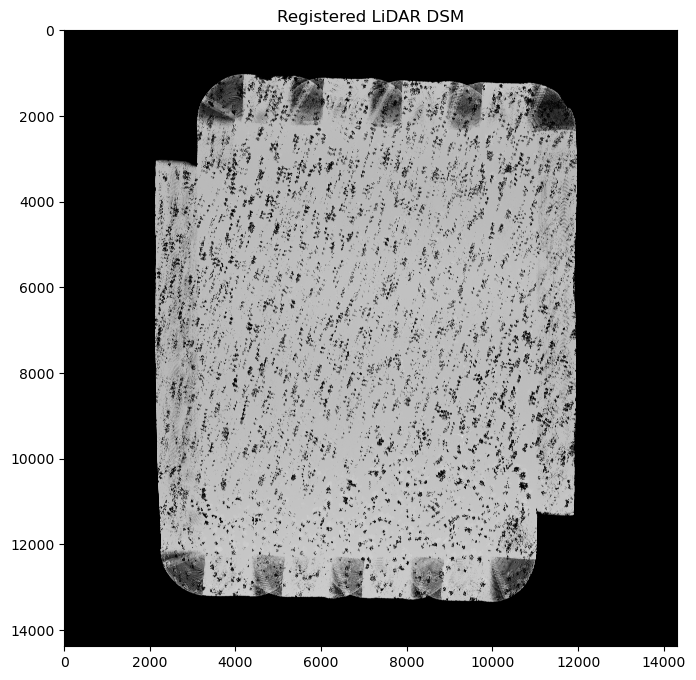

In [ ]:
# === Warp LiDAR DSM and Its Mask ===
print("🔹 Warping LiDAR DSM to RGB DSM space...")
imag_reg = wrapData(moving_data.astype('float64'), u, v)
warped_mask = wrapData(moving_mask.astype('float32'), u, v) > 0.5

pl.figure(figsize=(8,8))
pl.imshow(imag_reg, cmap='gray')
pl.title("Registered LiDAR DSM")
pl.show()

In [ ]:
# === Save Results ===
print("\n--- Saving Outputs ---")

flow_dir = base_image_path.parent
aligned_path = moving_image_path.with_name(moving_image_path.stem + "_coreg.tif")

with rasterio.open(base_image_path) as src:
    profile = src.profile
    transform = src.transform
    crs = src.crs
    nodata_value = src.nodata if src.nodata is not None else -9999.0

# Apply nodata mask
imag_reg[~warped_mask] = nodata_value

# Update profile and write
profile.update(dtype='float32', nodata=nodata_value, transform=transform, crs=crs)
with rasterio.open(aligned_path, "w", **profile) as dst:
    dst.write(imag_reg.astype('float32'), 1)

print(f"✅ Registered DSM saved to: {aligned_path}")

# Save optical flow fields
np.save(flow_dir / "flow_u_03_l2.npy", u)
np.save(flow_dir / "flow_v_03_l2.npy", v)
print(f"💾 Flow fields saved to: {flow_dir}")


--- Saving Outputs ---
✅ Registered DSM saved to: /data/calperumResearch/site1_1_DD0001/lidar_l2/dsm/crop_to_rgb/SASMDD0001_l2_dsm_03_coreg.tif
💾 Flow fields saved to: /data/calperumResearch/site1_1_DD0001/imagery/dsm


Registering image...



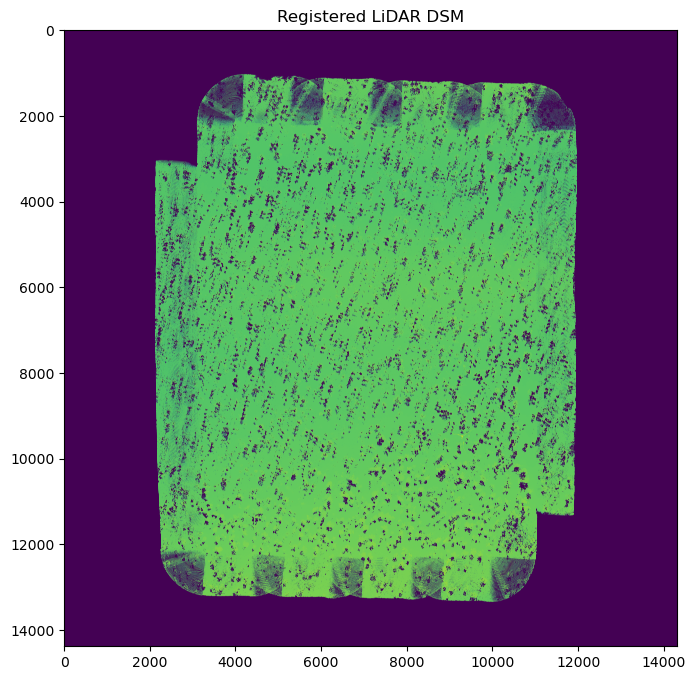

In [ ]:
# === Register the LiDAR data AND its footprint ===
print("Registering image...\n")
# 1. Warp the LiDAR elevation data
imag_reg = wrapData(moving_data, u, v)

# 2. Warp the LiDAR's original footprint (its mask) using the SAME flow field.
#    This is the key step to correctly track where the nodata areas should be.
warped_mask = wrapData(moving_mask.astype('float32'), u, v) > 0.5

pl.figure(figsize=(8,8)); pl.imshow(imag_reg); pl.title("Registered LiDAR DSM")
pl.show()

In [ ]:
# === Save Results ===
print("\n--- Saving Outputs ---")

flow_dir = base_image_path.parent
aligned_path = moving_image_path.with_name(moving_image_path.stem + "_coreg.tif")

with rasterio.open(base_image_path) as src:
    profile = src.profile
    transform = src.transform
    crs = src.crs
    nodata_value = src.nodata if src.nodata is not None else -9999.0

# Apply nodata mask
imag_reg[~warped_mask] = nodata_value

# Update profile and write
profile.update(dtype='float32', nodata=nodata_value, transform=transform, crs=crs)
with rasterio.open(aligned_path, "w", **profile) as dst:
    dst.write(imag_reg.astype('float32'), 1)

print(f"✅ Registered DSM saved to: {aligned_path}")

# Save optical flow fields
np.save(flow_dir / "flow_u_03_l2.npy", u)
np.save(flow_dir / "flow_v_03_l2.npy", v)
print(f"💾 Flow fields saved to: {flow_dir}")


--- Saving Outputs ---
✅ Registered DSM saved to: /data/calperumResearch/site1_1_DD0001/lidar_l2/dsm/crop_to_rgb/SASMDD0001_l2_dsm_03_coreg.tif
💾 Flow fields saved to: /data/calperumResearch/site1_1_DD0001/imagery/dsm


Connected to fvc_structure (Python 3.10.18)

In [ ]:
import sys
import numpy as np
import rasterio
import time
import pylab as pl
from pathlib import Path
from rasterio.warp import reproject, Resampling

# === GeFolki dependencies ===
# Workstation
# sys.path.append('/media/laura/laura_usb/code/fvc_structure/phase_1_image_processing/gefolki/python')
# === GeFolki dependencies === NVIDIA
sys.path.append('/home/nvidia/projects/fvc_structure/phase_2_lidar_coregistration/gefolki/python')

from python.algorithm import EFolki
from python.tools import wrapData

# === Configuration ===
Base_band = 0

# === Input paths ===
# Workstation
# base_image_path   = Path("/media/laura/laura_usb/uas_data/DD0001/imagery/dsm/SASMDD0001_rgb_dsm_03.tif")
# moving_image_path = Path("/media/laura/laura_usb/uas_data/DD0001/lidar_l2/dsm/crop_to_rgb/SASMDD0001_l2_dsm_03.tif")

# NVIDIA
# SITE 1
# base_image_path = Path("/data/calperumResearch/site1_1_DD0001/imagery/dsm/SASMDD0001_rgb_dsm_03.tif")
# moving_image_path = Path("/data/calperumResearch/site1_1_DD0001/lidar_l2/dsm/crop_to_rgb/SASMDD0001_l2_dsm_03.tif")

# SITE 11
base_image_path = Path("/data/calperumResearch/site2_1_DD0011/imagery/dsm/SASMDD0011_rgb_dsm_03.tif")
moving_image_path = Path("/data/calperumResearch/site2_1_DD0011/lidar_l2/dsm/crop_to_rgb/SASMDD0011_l2_dsm_03.tif")

In [ ]:
# === Function Definitions ===

def load_data_and_mask(path, band_idx):
    """Load raster band data with its valid data mask (True=valid, False=nodata)."""
    with rasterio.open(path) as src:
        if band_idx >= src.count:
            raise ValueError(f"Band {band_idx} out of range for {path}")
        valid_mask = src.read_masks(band_idx + 1) > 0
        arr = src.read(band_idx + 1).astype(np.float32)
        arr[~valid_mask] = 0
        return arr, valid_mask

def preprocess_dsm(arr, mask):
    """Remove absolute offset and normalize for EFolki."""
    arr = arr.astype(np.float32)
    arr[~mask] = np.nan
    arr = arr - np.nanmean(arr)          # remove mean (offset)
    arr = arr / (np.nanstd(arr) + 1e-6)  # standardize contrast
    arr[np.isnan(arr)] = 0
    return arr

In [ ]:
# === Load Input Rasters ===
base_data, base_mask = load_data_and_mask(base_image_path, Base_band)
moving_data, moving_mask = load_data_and_mask(moving_image_path, 0)

# === Verify Metadata Consistency ===
with rasterio.open(base_image_path) as base_src, rasterio.open(moving_image_path) as mov_src:
    if base_src.crs != mov_src.crs:
        print(f"⚠️ CRS mismatch: {base_src.crs} vs {mov_src.crs}")
    if base_src.res != mov_src.res:
        print(f"⚠️ Resolution mismatch: {base_src.res} vs {mov_src.res}")
    if base_src.transform != mov_src.transform:
        print("⚠️ Pixel grid differs → Reprojecting LiDAR DSM to RGB grid.")
        dst = np.empty_like(base_data)
        reproject(
            source=moving_data,
            destination=dst,
            src_transform=mov_src.transform,
            src_crs=mov_src.crs,
            dst_transform=base_src.transform,
            dst_crs=base_src.crs,
            resampling=Resampling.bilinear
        )
        moving_data = dst

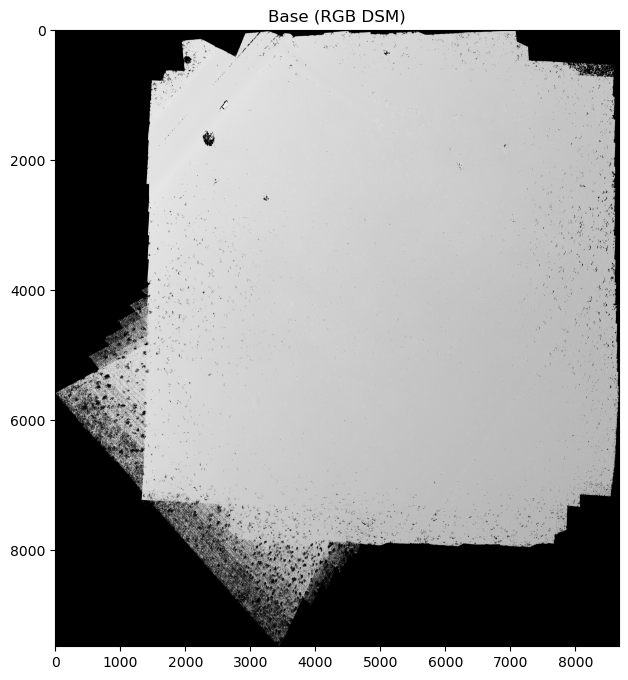

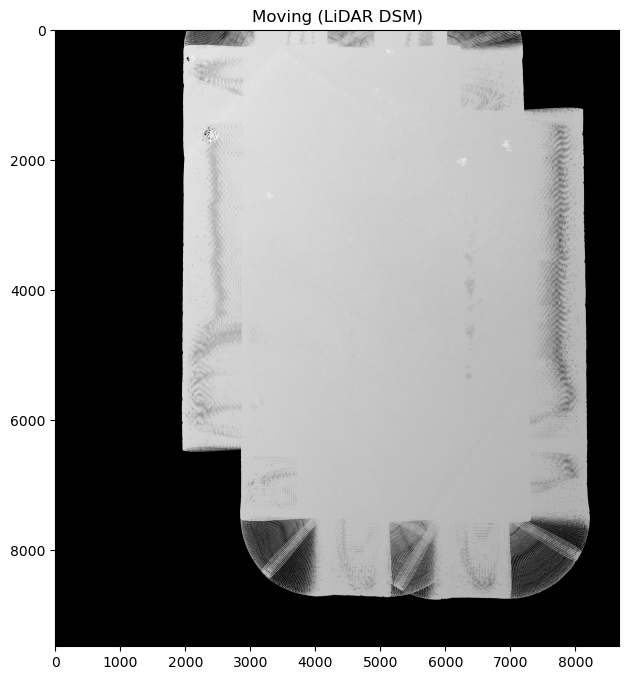

In [ ]:
# === Initial Visualization ===
pl.figure(figsize=(8,8))
pl.imshow(base_data, cmap='gray')
pl.title("Base (RGB DSM)")

pl.figure(figsize=(8,8))
pl.imshow(moving_data, cmap='gray')
pl.title("Moving (LiDAR DSM)")

pl.show()

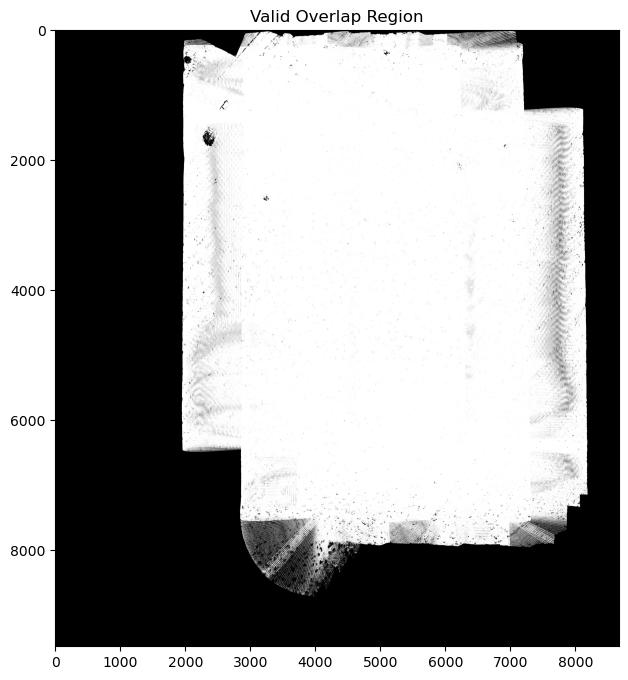

In [ ]:
# === Define Processing Mask ===
processing_mask = base_mask & moving_mask
base_data[~processing_mask] = 0
moving_data[~processing_mask] = 0

pl.figure(figsize=(8,8))
pl.imshow(processing_mask, cmap='gray')
pl.title("Valid Overlap Region")
pl.show()

In [ ]:
# === Normalize Inputs ===
base_norm   = preprocess_dsm(base_data, processing_mask)
moving_norm = preprocess_dsm(moving_data, processing_mask)

🔹 Calculating optical flow (EFolki)...
✅ Flow calculated in 14.600 minutes
Mean flow: u=20.066, v=-20.974, std(u)=21.087, std(v)=22.107


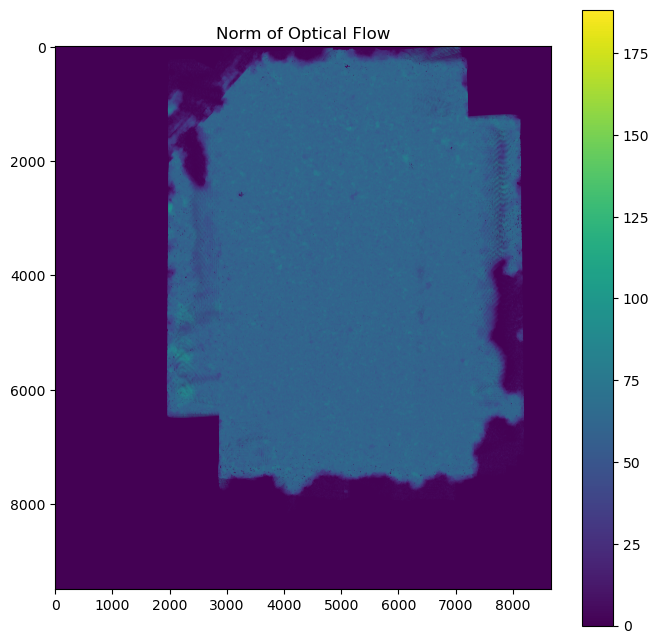

In [ ]:
# === Run GeFolki Optical Flow ===
print("🔹 Calculating optical flow (EFolki)...")
t0 = time.perf_counter()

u, v = EFolki(base_norm, moving_norm,
              iteration=8,
              radius=[8, 4, 2],
              rank=4,
              levels=6)

t1 = time.perf_counter()
print(f"✅ Flow calculated in {(t1 - t0)/60:.3f} minutes")

# Mask flow outside valid region
u[~processing_mask] = 0
v[~processing_mask] = 0

# Flow diagnostics
print(f"Mean flow: u={np.nanmean(u):.3f}, v={np.nanmean(v):.3f}, std(u)={np.nanstd(u):.3f}, std(v)={np.nanstd(v):.3f}")

# Visualize flow norm
N = np.sqrt(u**2 + v**2)
pl.figure(figsize=(8,8))
pl.imshow(N, cmap='viridis')
pl.title("Norm of Optical Flow")
pl.colorbar()
pl.show()

Registering image...



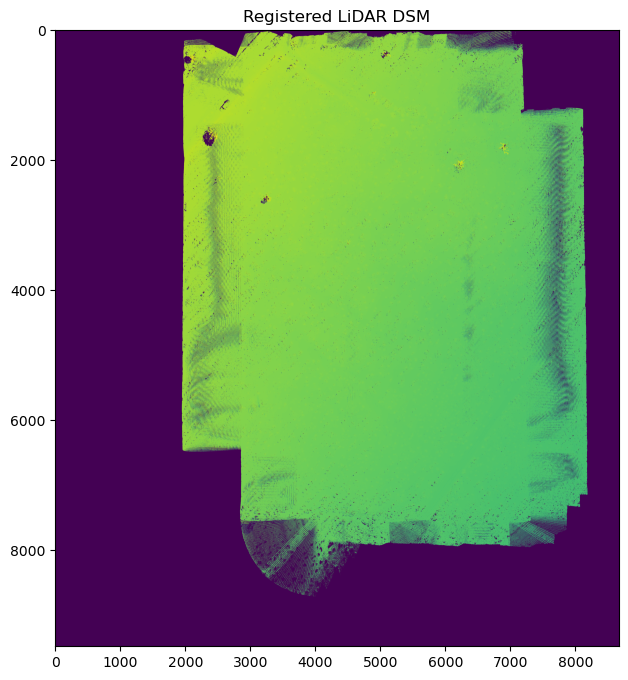

In [ ]:
#same as before but palette changed
# === Register the LiDAR data AND its footprint ===
print("Registering image...\n")
# 1. Warp the LiDAR elevation data
imag_reg = wrapData(moving_data, u, v)

# 2. Warp the LiDAR's original footprint (its mask) using the SAME flow field.
#    This is the key step to correctly track where the nodata areas should be.
warped_mask = wrapData(moving_mask.astype('float32'), u, v) > 0.5

pl.figure(figsize=(8,8)); pl.imshow(imag_reg); pl.title("Registered LiDAR DSM")
pl.show()

In [ ]:
# === Save Results ===
print("\n--- Saving Outputs ---")

flow_dir = base_image_path.parent
aligned_path = moving_image_path.with_name(moving_image_path.stem + "_coreg.tif")

with rasterio.open(base_image_path) as src:
    profile = src.profile
    transform = src.transform
    crs = src.crs
    nodata_value = src.nodata if src.nodata is not None else -9999.0

# Apply nodata mask
imag_reg[~warped_mask] = nodata_value

# Update profile and write
profile.update(dtype='float32', nodata=nodata_value, transform=transform, crs=crs)
with rasterio.open(aligned_path, "w", **profile) as dst:
    dst.write(imag_reg.astype('float32'), 1)

print(f"✅ Registered DSM saved to: {aligned_path}")

# Save optical flow fields
np.save(flow_dir / "flow_u_03_l2.npy", u)
np.save(flow_dir / "flow_v_03_l2.npy", v)
print(f"💾 Flow fields saved to: {flow_dir}")


--- Saving Outputs ---
✅ Registered DSM saved to: /data/calperumResearch/site2_1_DD0011/lidar_l2/dsm/crop_to_rgb/SASMDD0011_l2_dsm_03_coreg.tif
💾 Flow fields saved to: /data/calperumResearch/site2_1_DD0011/imagery/dsm
